# 119 · is the [cls] query a naive average over bands / lasers?
Question: *looking at the keys for the CLS query, are we doing a naive average over all freqs and lasers, learning no pattern?*

Two 200-ep `transformer2` runs (same data / recipe):

| run | freq stage readout (18 bands → 1 token per laser) | laser stage (100 lasers → latent) | ID IoU@.08 |
|---|---|---|---|
| `s9-t2-cls-vase-200` | `freq_cls` token, 2 blocks | `laser_cls` token, 2 blocks, LN + Linear(128→1024) | .344 (nb116) |
| `s9-t2-ref-vase-200` | gate: softmax(pool_q · pool_k(band)) over bands, then flatten + Linear | self-attention, no cls, flatten + Linear(12,800→1024) | .679 (nb118) |

Per stage, layer and head of the cls row (attention renormalized over the 18 bands / 100 lasers, self weight reported separately):
1. **static pattern** = mean attention over samples: TV distance to uniform, max/min weight.
2. **per-sample variation**: TV(sample, static pattern).
3. **entropy / log T** (1 = uniform).
4. **PE vs content** in the score s_b = q_cls·k_b: (a) variance split of the row-centered score into a fixed-per-position part (mean over samples) and a
   sample-dependent part; (b) layer 0 only: recompute scores with the content zeroed (PE only) and with the PE zeroed (content only), R² vs the real score.
5. **causal**: set the cls row to uniform 1/T at eval (each stage, all its layers) and measure the ID IoU@.08 drop.

Already known (reused, not recomputed): nb116 cls run: freq_cls entropy .92–.98, laser_cls last-layer entropy .907, TV sample→mean .278 vs mean→uniform .206.
nb117: ref gate=1 drop −.011 ID. nb118: on `lasercls` (no freq_cls) uniform laser_cls costs .549 → .194.

fp32, GPU (inference, small batches), 300 ID-eval samples (id + multiple splits, as nb113/nb118).

In [1]:
import os, sys, math, json
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False   # fp32
GRID = {"cls": "s9-t2-cls-vase-200", "ref": "s9-t2-ref-vase-200"}
FLAGS = ("freq_cls", "laser_cls", "band_proj", "laser_proj")
ARGS = {r: {k: json.load(open(ROOT / "runs" / n / "args.json")).get(k, 0) for k in FLAGS} for r, n in GRID.items()}
SD = {r: torch.load(ROOT / f"runs/{n}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"] for r, n in GRID.items()}
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
pd.DataFrame(ARGS).T

,freq_cls,laser_cls,band_proj,laser_proj
cls,1,1,0,0
ref,0,0,0,0


In [2]:
# 300 ID eval samples (id + multiple splits), as nb118
ev = []
for f in sorted((ROOT / f"runs/{GRID['ref']}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    c = CAT.get((f.parent.parent.name, f.parent.name))
    if c not in ("id", "multiple"): continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    ev += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
SEL = [ev[i] for i in np.random.choice(len(ev), 300, replace=False)]
X, BOXN, Y = [], [], []
for exp, sid, pos, spk in SEL:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float()); BOXN.append(meta["box"]); Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y = torch.stack(X), np.stack(Y); N = len(X)
NAMES = ["cardboard", "gastronorm", "green-plastic"]; BOX = torch.tensor([NAMES.index(b) for b in BOXN])

def build(r):
    sd = SD[r]; nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, **ARGS[r]); m.load_state_dict(sd, strict=True)
    return m.eval().to(DEV)
M = {r: build(r) for r in GRID}
print("X", tuple(X.shape), "boxes", pd.Series(BOXN).value_counts().to_dict())

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


X (300, 100, 1170, 2) boxes {'green-plastic': 114, 'cardboard': 109, 'gastronorm': 77}


## the encoder written out (from nb118's `block` / `encode`)
Keeps, per block, the cls row's **pre-softmax scores** and attention, and allows the cls row (ref: the gate) to be set to uniform.
`pe_only` / `content_only` (layer 0 only, no effect on the forward): the cls scores recomputed from tokens with the content or the position embeddings zeroed.
Freq stage token = `embed(x_b)` (content) + `freq_band_emb[b] + laser[l]` (PE) + `box_emb` (kept in both); content zeroed = x = 0 (embed bias stays).
Laser stage token = `raw_l` (freq-stage output = content) + `laser[l]` (PE).

In [3]:
def block(blk, x, uniform_cls=False):
    # Block.forward written out: returns (new x, attention (N,H,T,T), cls-row scores (N,H,T))
    N_, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N_, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    s = q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1]); a = s.softmax(-1)
    if uniform_cls: a = a.clone(); a[:, :, 0, :] = 1 / T
    x = x + blk.o((a @ v).transpose(1, 2).reshape(N_, T, D))
    return x + blk.mlp(blk.n2(x)), a, s[:, :, 0]

def cls_scores(blk, cls, toks):
    # scores of the cls query (fixed token, layer 0) against arbitrary key tokens: (N,T,D) -> (N,H,T)
    N_, T, D = toks.shape
    x = torch.cat([cls.expand(N_, 1, -1), toks], 1)
    q, k, _ = blk.qkv(blk.n1(x)).view(N_, T + 1, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    return (q[:, :, :1] @ k.transpose(-1, -2) / math.sqrt(q.shape[-1]))[:, :, 0]

@torch.no_grad()
def encode(m, x, bx, uni_freq=False, uni_laser=False):
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]; out = {}
    xn = e.normalize(x, bx).reshape(B, L, 18, -1)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)                                      # (L,128) laser PE
    content = fe.embed(xn) + fe.box_emb(bx)[:, None, None]                                   # (B,L,18,128)
    pe = fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None]       # (1,L,18,128)
    t = (content + pe).flatten(0, 1)
    if fe.cls:
        out["f_pe_s"] = cls_scores(fe.freqs[0], fe.freq_cls, (fe.embed.bias + fe.box_emb(bx)[:, None, None] + pe).flatten(0, 1))[..., 1:].reshape(B, L, -1, 18)
        out["f_ct_s"] = cls_scores(fe.freqs[0], fe.freq_cls, content.flatten(0, 1))[..., 1:].reshape(B, L, -1, 18)
        t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1); A, S = [], []
        for blk in fe.freqs: t, a, s = block(blk, t, uni_freq); A.append(a[:, :, 0]); S.append(s)
        out["f_attn"] = torch.stack(A, 1).view(B, L, len(A), fe.heads, 19)               # incl. self weight at index 0
        out["f_s"] = torch.stack(S, 1).view(B, L, len(S), fe.heads, 19)[..., 1:]
        raw = t[:, 0].view(B, L, -1)
    else:
        for blk in fe.freqs: t, _, _ = block(blk, t)
        t = t.view(B, L, 18, -1); k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        s = torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1]))      # (B,L,H,18) gate scores
        g = s.softmax(-1)
        out["gate"], out["gate_s"] = g, s
        gm = torch.ones_like(g.mean(2)) if uni_freq else g.mean(2) * 18
        raw = fe.pool_o((t * gm[..., None]).reshape(B, L, -1))
    z = raw + laser
    if le.cls:
        out["l_pe_s"] = cls_scores(le.lasers[0], le.laser_cls, laser[None].expand(B, -1, -1))[..., 1:]
        out["l_ct_s"] = cls_scores(le.lasers[0], le.laser_cls, raw)[..., 1:]
        z = torch.cat([le.laser_cls.expand(B, 1, -1), z], 1); A, S = [], []
        for blk in le.lasers: z, a, s = block(blk, z, uni_laser); A.append(a[:, :, 0]); S.append(s[..., 1:])
        out["l_attn"], out["l_s"] = torch.stack(A, 1), torch.stack(S, 1)                    # (B,layers,H,101) incl self, (B,layers,H,100)
        emb = le.to_emb(z[:, 0])
    else:
        A = []
        for blk in le.lasers: z, a, _ = block(blk, z); A.append(a)
        out["l_full"] = torch.stack(A, 1)                                                    # (B,layers,H,100,100)
        emb = le.to_emb(z)
    out["mask"] = m.decoder(emb)[:, 0].sigmoid()
    return out

def run(m, bs=10, **kw):
    outs = []
    for i in range(0, N, bs):
        o = encode(m, X[i:i + bs].to(DEV), BOX[i:i + bs].to(DEV), **kw); outs.append({k: v.cpu() for k, v in o.items()})
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}

def iou(P, thr=.08): return np.array([((P[i] > thr) & (Y[i] > .5)).sum() / max(((P[i] > thr) | (Y[i] > .5)).sum(), 1) for i in range(N)])
with torch.no_grad():
    for r, m in M.items():
        assert torch.allclose(m.decoder(m.encoder(X[:4].to(DEV), BOX[:4].to(DEV)))[:, 0].sigmoid().cpu(), encode(m, X[:4].to(DEV), BOX[:4].to(DEV))["mask"].cpu(), atol=1e-4), r
O = {r: run(m) for r, m in M.items()}
print("ID IoU@.08 on these 300 samples:", {r: round(iou(O[r]["mask"].numpy()).mean(), 3) for r in O}, "(logged ID: cls .344 (nb116), ref .679)")

ID IoU@.08 on these 300 samples: {'cls': np.float64(0.365), 'ref': np.float64(0.691)} (logged ID: cls .344 (nb116), ref .679)


## 1–4 · the cls run: static pattern, per-sample variation, entropy, PE vs content
For the freq stage the static pattern is the mean over samples **per laser** (the PE includes the laser), and the TVs are averaged over lasers.
`static_share` = share of the row-centered score variance (over samples × positions [× lasers]) that is the per-position mean over samples
(= fixed by position); `sample_share` = the rest (input-dependent). `R2_pe_only` / `R2_content_only` (layer 0): R² of the real row-centered score from the score with the content / PE zeroed.

In [4]:
def ent(a): return (-(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(a.shape[-1]))
def tv(a, b): return (a - b).abs().sum(-1) / 2
def rc(s): return s - s.mean(-1, keepdim=True)                                              # row-center: softmax ignores a per-row shift
def r2(pred, y):
    pred, y = rc(pred).flatten(), rc(y).flatten(); b = (pred @ y) / (pred @ pred)            # one scale fitted
    return 1 - ((y - b * pred) ** 2).sum().item() / (y ** 2).sum().item()

def stats(a, s, static_dims, pe=None, ct=None):
    # a: attention over positions (last dim, renormalized), s: scores. static = mean over sample dim 0 (keeping static_dims)
    P = a.shape[-1]; m = a.mean(0, keepdim=True); sc = rc(s); sm = sc.mean(0, keepdim=True)
    d = dict(entropy=ent(a).mean().item(), tv_static_vs_uniform=tv(m, torch.full_like(m, 1 / P)).mean().item(),
             static_max_x_uniform=(m.max(-1).values * P).mean().item(), static_min_x_uniform=(m.min(-1).values * P).mean().item(),
             tv_sample_vs_static=tv(a, m).mean().item(), static_share=(sm.expand_as(sc) ** 2).sum().item() / (sc ** 2).sum().item())
    d["sample_share"] = 1 - d["static_share"]
    if pe is not None: d |= dict(R2_pe_only=r2(pe, s), R2_content_only=r2(ct, s))
    return d

o = O["cls"]; R = []
fa = o["f_attn"]; fb = fa[..., 1:] / fa[..., 1:].sum(-1, keepdim=True)                     # (N,L,layers,H,18) renormalized over bands
for l in range(fa.shape[2]):
    for h in range(fa.shape[3]):
        R.append(dict(stage="freq (18 bands)", layer=l, head=h, self_w=fa[:, :, l, h, 0].mean().item(),
                      **stats(fb[:, :, l, h], o["f_s"][:, :, l, h], 1, *( (o["f_pe_s"][:, :, h], o["f_ct_s"][:, :, h]) if l == 0 else (None, None)))))
la = o["l_attn"]; lb = la[..., 1:] / la[..., 1:].sum(-1, keepdim=True)                     # (N,layers,H,100)
for l in range(la.shape[1]):
    for h in range(la.shape[2]):
        R.append(dict(stage="laser (100 lasers)", layer=l, head=h, self_w=la[:, l, h, 0].mean().item(),
                      **stats(lb[:, l, h], o["l_s"][:, l, h], 0, *((o["l_pe_s"][:, h], o["l_ct_s"][:, h]) if l == 0 else (None, None)))))
R = pd.DataFrame(R)
print("cls run, cls row per layer / head. uniform: entropy 1, TV 0, max = min = 1x uniform"); display(R.round(3))
display(R.groupby(["stage", "layer"]).mean(numeric_only=True).drop(columns="head").round(3))

cls run, cls row per layer / head. uniform: entropy 1, TV 0, max = min = 1x uniform


,stage,layer,head,self_w,entropy,tv_static_vs_uniform,static_max_x_uniform,static_min_x_uniform,tv_sample_vs_static,static_share,sample_share,R2_pe_only,R2_content_only
0,freq (18 bands),0,0,0.027,0.969,0.138,2.000,0.655,0.102,0.594,0.406,0.594,0.382
1,freq (18 bands),0,1,0.043,0.980,0.079,1.511,0.786,0.110,0.315,0.685,0.314,0.677
2,freq (18 bands),0,2,0.031,0.996,0.012,1.079,0.962,0.059,0.041,0.959,0.035,0.958
3,freq (18 bands),0,3,0.054,0.987,0.015,1.073,0.931,0.111,0.017,0.983,0.009,0.993
4,freq (18 bands),1,0,0.063,0.981,0.017,1.073,0.923,0.128,0.015,0.985,NaN,NaN
5,freq (18 bands),1,1,0.052,0.982,0.016,1.096,0.938,0.125,0.016,0.984,NaN,NaN
6,freq (18 bands),1,2,0.100,0.985,0.021,1.127,0.926,0.116,0.028,0.972,NaN,NaN
7,freq (18 bands),1,3,0.116,0.979,0.017,1.091,0.931,0.135,0.013,0.987,NaN,NaN
8,laser (100 lasers),0,0,0.006,0.766,0.531,10.409,0.017,0.212,0.837,0.163,0.681,0.559
9,laser (100 lasers),0,1,0.003,0.755,0.541,10.951,0.027,0.205,0.861,0.139,0.796,0.568


self_w  entropy  tv_static_vs_uniform  static_max_x_uniform  static_min_x_uniform  tv_sample_vs_static  static_share  sample_share  R2_pe_only  R2_content_only
stage              layer                                                                                                                                                                 
freq (18 bands)    0       0.039    0.983                 0.061                 1.416                 0.834                0.095         0.242         0.758       0.238            0.753
                   1       0.083    0.982                 0.018                 1.097                 0.929                0.126         0.018         0.982         NaN              NaN
laser (100 lasers) 0       0.004    0.775                 0.527                 9.254                 0.015                0.201         0.873         0.127       0.792            0.605
                   1       0.008    0.833                 0.295                 6.924                 0.243                0.358         0.378         0.622         NaN              NaN

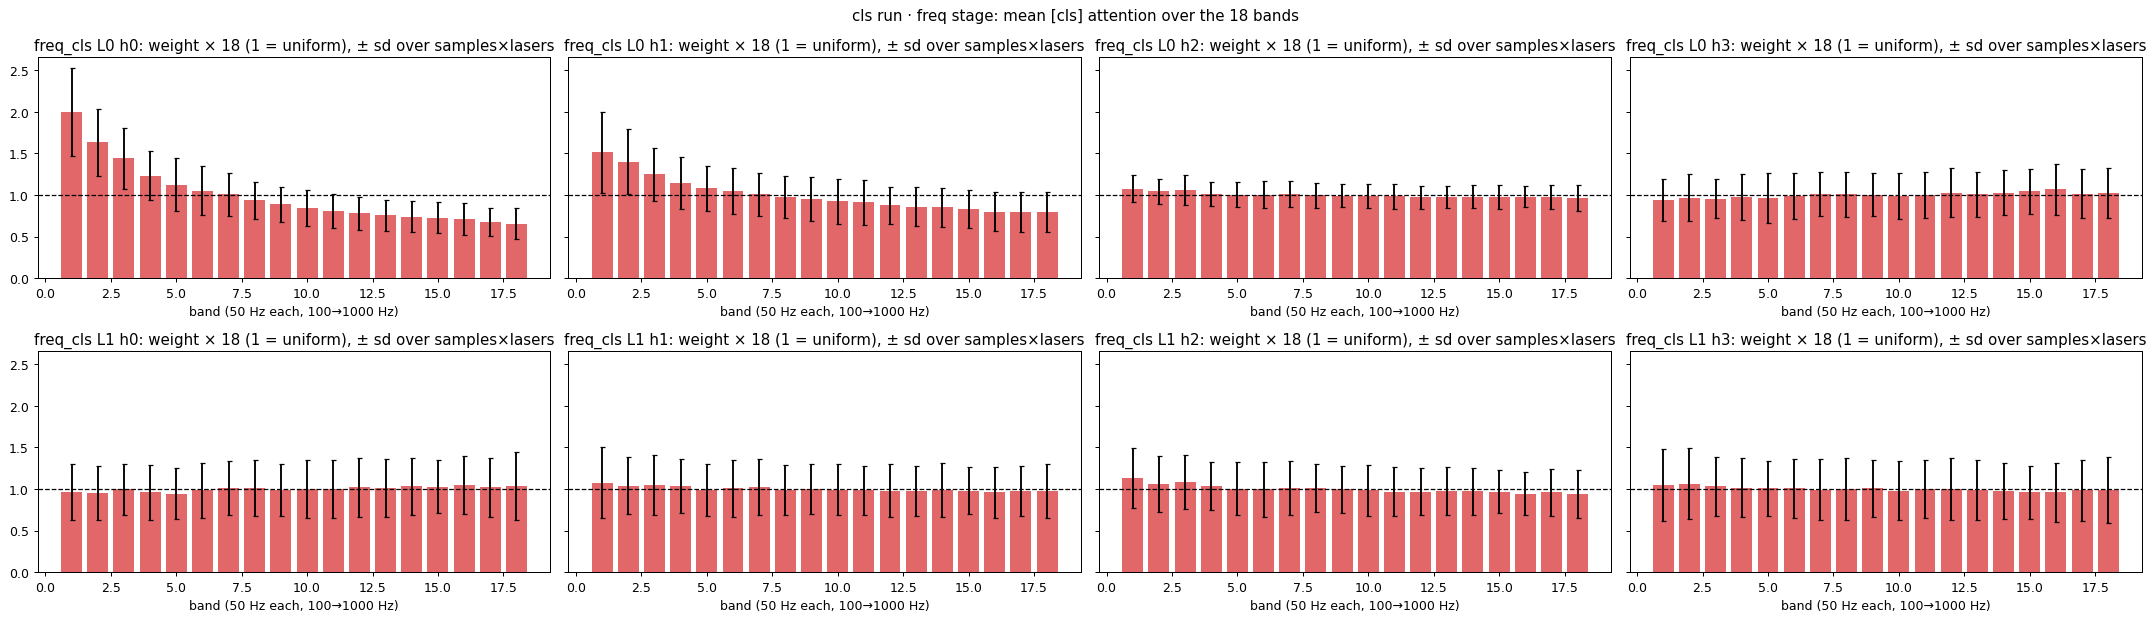

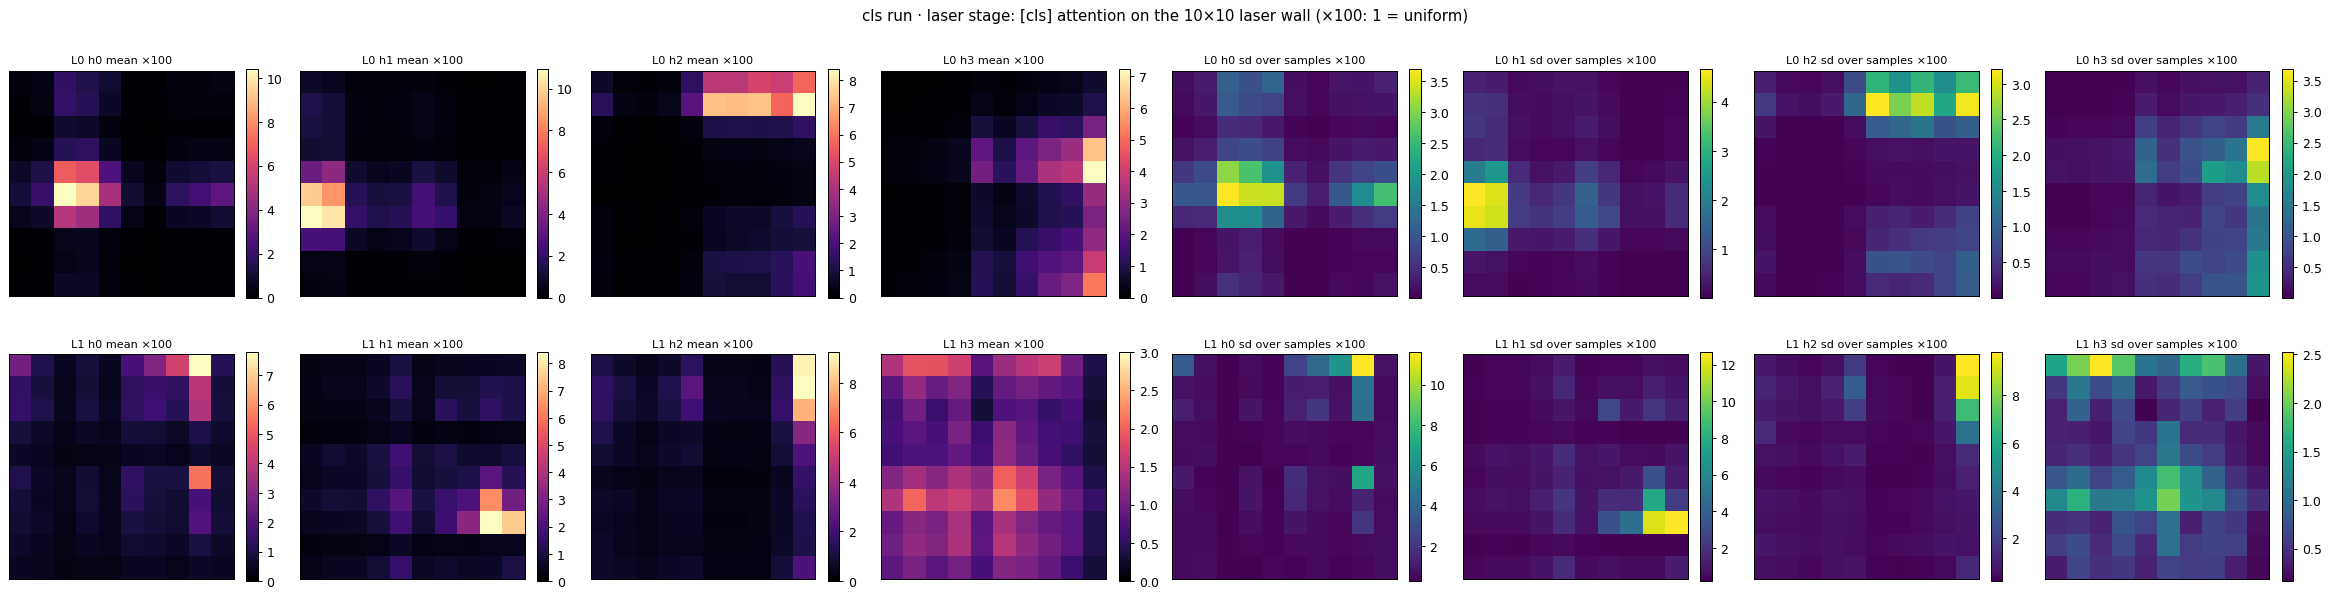

In [5]:
fig, axs = plt.subplots(2, 4, figsize=(24, 7), sharey=True)
for l in range(2):
    for h in range(4):
        ax = axs[l, h]; w = fb[:, :, l, h].flatten(0, 1); mu, sd = w.mean(0), w.std(0)
        ax.bar(range(1, 19), mu * 18, yerr=sd * 18, color="tab:red", alpha=.7, capsize=2); ax.axhline(1, color="k", ls="--", lw=1)
        ax.set(title=f"freq_cls L{l} h{h}: weight × 18 (1 = uniform), ± sd over samples×lasers", xlabel="band (50 Hz each, 100→1000 Hz)")
plt.suptitle("cls run · freq stage: mean [cls] attention over the 18 bands"); plt.tight_layout(); plt.show()

fig, axs = plt.subplots(2, 8, figsize=(26, 7))
for l in range(2):
    for h in range(4):
        mu, sd = lb[:, l, h].mean(0) * 100, lb[:, l, h].std(0) * 100
        im = axs[l, h].imshow(mu.view(10, 10), cmap="magma", vmin=0, vmax=max(3, mu.max().item())); axs[l, h].set_title(f"L{l} h{h} mean ×100", fontsize=9); plt.colorbar(im, ax=axs[l, h], fraction=.046)
        im = axs[l, 4 + h].imshow(sd.view(10, 10), cmap="viridis"); axs[l, 4 + h].set_title(f"L{l} h{h} sd over samples ×100", fontsize=9); plt.colorbar(im, ax=axs[l, 4 + h], fraction=.046)
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("cls run · laser stage: [cls] attention on the 10×10 laser wall (×100: 1 = uniform)"); plt.tight_layout(); plt.show()

## 5 · causal: cls row → uniform at eval
`uniform freq`: the [cls] row of both freq blocks attends 1/19 to everything (incl. itself); `uniform laser`: same for both laser blocks (1/101). ref: gate = 1 (nb117 measured −.011 on its own 300 ID samples).

In [6]:
base = {r: iou(O[r]["mask"].numpy()) for r in O}
U = {"cls": {"as trained": base["cls"].mean()}, "ref": {"as trained": base["ref"].mean()}}
for name, kw in [("uniform freq", dict(uni_freq=True)), ("uniform laser", dict(uni_laser=True)), ("uniform both", dict(uni_freq=True, uni_laser=True))]:
    U["cls"][name] = iou(run(M["cls"], **kw)["mask"].numpy()).mean()
U["ref"]["uniform freq"] = iou(run(M["ref"], uni_freq=True)["mask"].numpy()).mean()
U = pd.DataFrame(U).T
D = U.drop(columns="as trained").rsub(U["as trained"], axis=0)
print("ID IoU@.08 (300 samples)"); display(U.round(3)); print("drop (as trained − ablated)"); display(D.round(3))

ID IoU@.08 (300 samples)


,as trained,uniform freq,uniform laser,uniform both
cls,0.365,0.194,0.042,0.035
ref,0.691,0.684,NaN,NaN


drop (as trained − ablated)


,uniform freq,uniform laser,uniform both
cls,0.172,0.323,0.331
ref,0.007,NaN,NaN


## ref, for comparison
**freq gate**: softmax(pool_q · pool_k(band)) per head over the 18 bands (the model then averages the 4 heads and multiplies by 18).
**laser self-attention** (no cls): entropy over the 100 keys for every query laser, and the mean pattern for a corner, an edge and a centre query laser.

ref


,what,layer,head,entropy,tv_static_vs_uniform,static_max_x_uniform,static_min_x_uniform,tv_sample_vs_static,static_share,sample_share,self_w
0,freq gate,-,0,0.995,0.007,1.032,0.969,0.064,0.011,0.989,NaN
1,freq gate,-,1,0.995,0.007,1.032,0.969,0.066,0.011,0.989,NaN
2,freq gate,-,2,0.995,0.007,1.032,0.967,0.065,0.012,0.988,NaN
3,freq gate,-,3,0.996,0.007,1.030,0.969,0.059,0.012,0.988,NaN
4,"freq gate (head mean, used)",-,mean,0.996,0.007,1.031,0.969,0.063,0.012,0.988,NaN
5,laser self-attn (all 100 queries),0,0,0.990,0.037,1.256,0.820,0.114,NaN,NaN,0.010
6,laser self-attn (all 100 queries),0,1,0.990,0.034,1.229,0.825,0.117,NaN,NaN,0.011
7,laser self-attn (all 100 queries),0,2,0.990,0.032,1.225,0.840,0.113,NaN,NaN,0.010
8,laser self-attn (all 100 queries),0,3,0.989,0.034,1.229,0.832,0.120,NaN,NaN,0.010
9,laser self-attn (all 100 queries),1,0,0.989,0.034,1.245,0.829,0.119,NaN,NaN,0.009


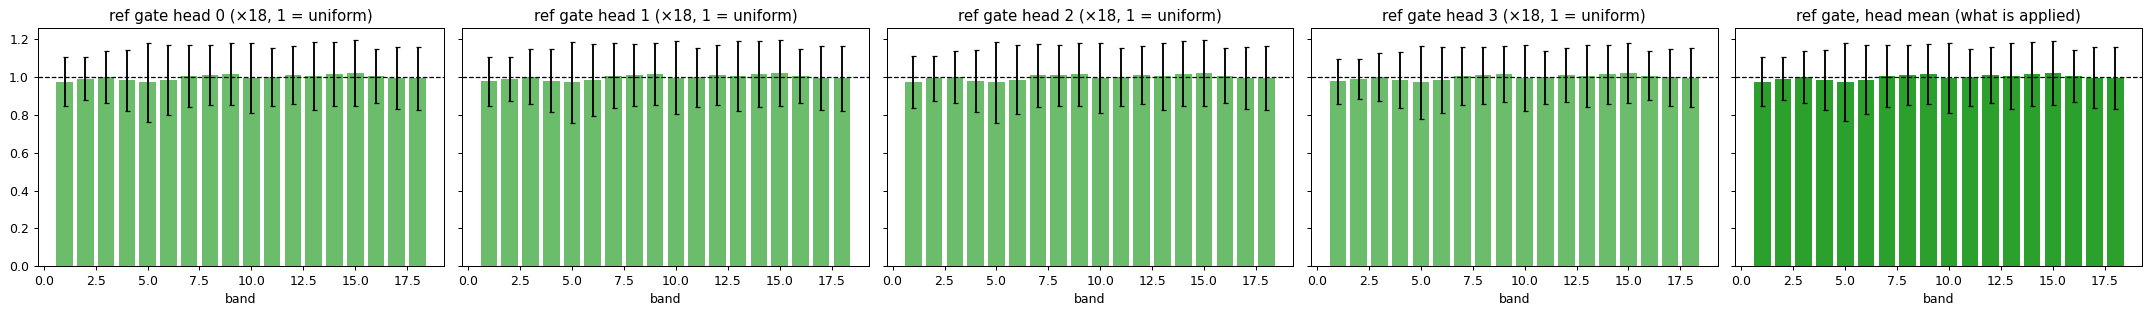

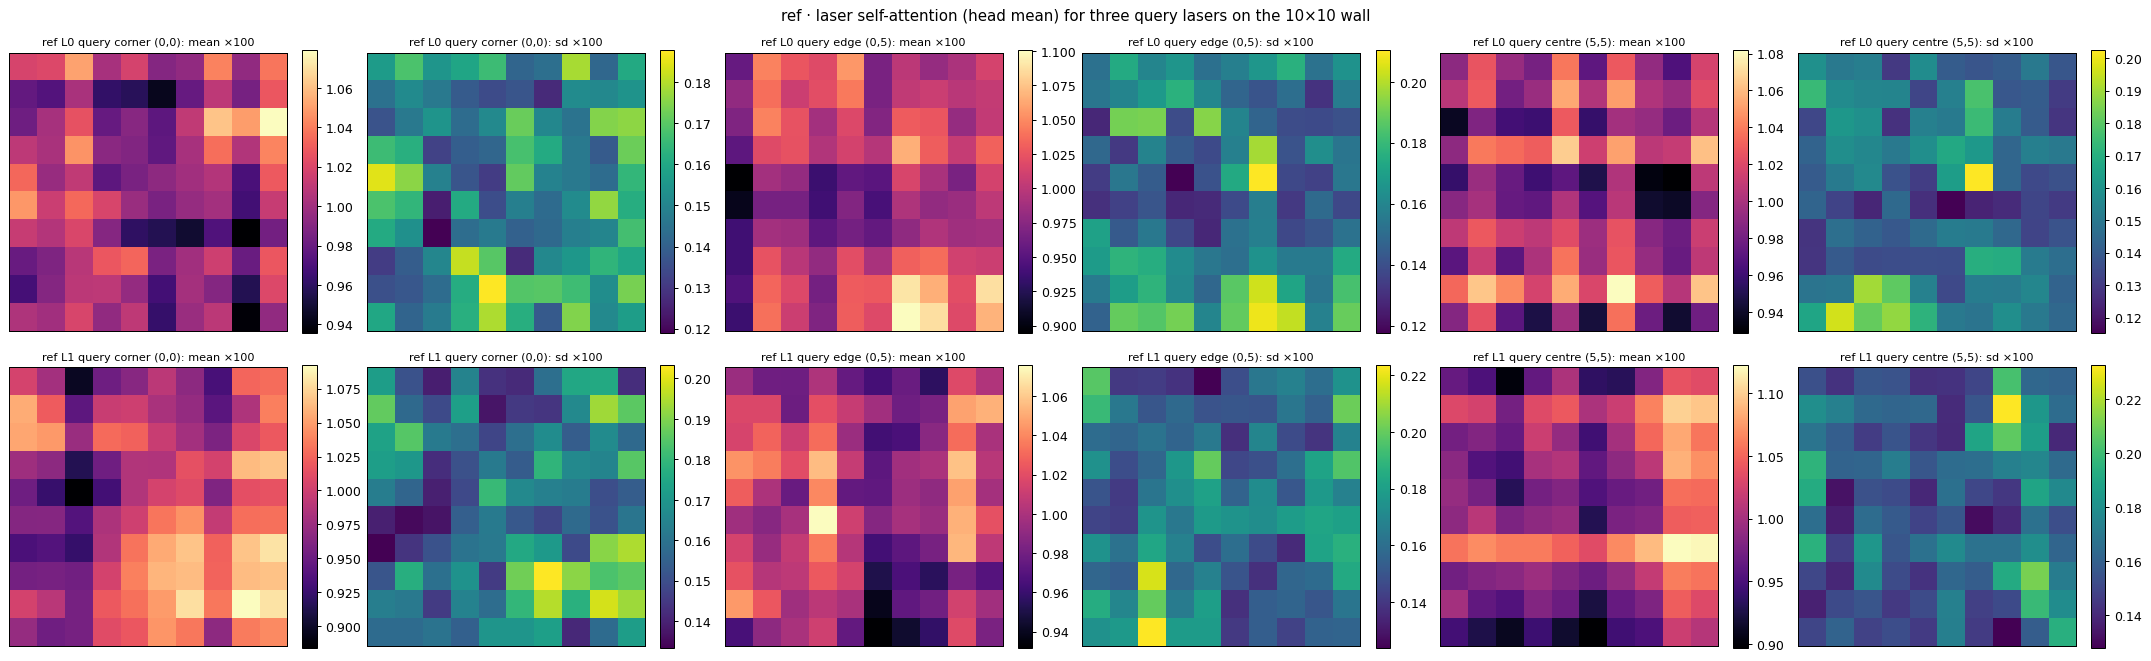

In [7]:
o = O["ref"]; RR = []
g = o["gate"]                                                                                # (N,L,H,18)
for h in range(g.shape[2]): RR.append(dict(what="freq gate", layer="-", head=h, **stats(g[:, :, h], o["gate_s"][:, :, h], 1)))
gm = g.mean(2); RR.append(dict(what="freq gate (head mean, used)", layer="-", head="mean", **stats(gm, gm.log(), 1)))
lf = o["l_full"]                                                                            # (N,layers,H,100 q,100 k)
for l in range(lf.shape[1]):
    for h in range(lf.shape[2]):
        a = lf[:, l, h]; m = a.mean(0, keepdim=True)
        RR.append(dict(what="laser self-attn (all 100 queries)", layer=l, head=h, entropy=ent(a).mean().item(), tv_static_vs_uniform=tv(m, torch.full_like(m, .01)).mean().item(),
                       static_max_x_uniform=(m.max(-1).values * 100).mean().item(), static_min_x_uniform=(m.min(-1).values * 100).mean().item(), tv_sample_vs_static=tv(a, m).mean().item(),
                       self_w=torch.diagonal(a, dim1=-2, dim2=-1).mean().item()))
RR = pd.DataFrame(RR); print("ref"); display(RR.round(3))

fig, axs = plt.subplots(1, 5, figsize=(24, 3.6), sharey=True)
for h in range(4):
    w = g[:, :, h].flatten(0, 1) * 18; axs[h].bar(range(1, 19), w.mean(0), yerr=w.std(0), color="tab:green", alpha=.7, capsize=2); axs[h].set_title(f"ref gate head {h} (×18, 1 = uniform)")
w = gm.flatten(0, 1) * 18; axs[4].bar(range(1, 19), w.mean(0), yerr=w.std(0), color="tab:green", capsize=2); axs[4].set_title("ref gate, head mean (what is applied)")
for ax in axs: ax.axhline(1, color="k", ls="--", lw=1); ax.set_xlabel("band")
plt.tight_layout(); plt.show()

Q = {"corner (0,0)": 0, "edge (0,5)": 5, "centre (5,5)": 55}
fig, axs = plt.subplots(2, 6, figsize=(24, 7.5))
for l in range(2):
    for j, (nm, q) in enumerate(Q.items()):
        a = lf[:, l, :, q].mean(1)                                                           # mean over heads (N,100)
        im = axs[l, 2 * j].imshow(a.mean(0).view(10, 10) * 100, cmap="magma"); axs[l, 2 * j].set_title(f"ref L{l} query {nm}: mean ×100", fontsize=9); plt.colorbar(im, ax=axs[l, 2 * j], fraction=.046)
        im = axs[l, 2 * j + 1].imshow(a.std(0).view(10, 10) * 100, cmap="viridis"); axs[l, 2 * j + 1].set_title(f"ref L{l} query {nm}: sd ×100", fontsize=9); plt.colorbar(im, ax=axs[l, 2 * j + 1], fraction=.046)
for ax in axs.flat: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("ref · laser self-attention (head mean) for three query lasers on the 10×10 wall"); plt.tight_layout(); plt.show()

In [8]:
# one summary table: per stage, averaged over layers and heads (cls) / heads (ref gate)
S = R.groupby("stage").mean(numeric_only=True)[["entropy", "tv_static_vs_uniform", "static_max_x_uniform", "static_min_x_uniform", "tv_sample_vs_static", "static_share", "R2_pe_only", "R2_content_only"]]
S.index = [f"cls · {i}" for i in S.index]
S.loc["cls · freq (18 bands)", "uniform_drop"] = D.loc["cls", "uniform freq"]; S.loc["cls · laser (100 lasers)", "uniform_drop"] = D.loc["cls", "uniform laser"]
gg = RR[RR.what == "freq gate"].mean(numeric_only=True); S.loc["ref · freq gate"] = gg[S.columns.intersection(gg.index)]; S.loc["ref · freq gate", "uniform_drop"] = D.loc["ref", "uniform freq"]
ll = RR[RR.what.str.startswith("laser")].mean(numeric_only=True); S.loc["ref · laser self-attn"] = ll[S.columns.intersection(ll.index)]
display(S.round(3))

,entropy,tv_static_vs_uniform,static_max_x_uniform,static_min_x_uniform,tv_sample_vs_static,static_share,R2_pe_only,R2_content_only,uniform_drop
cls · freq (18 bands),0.982,0.039,1.256,0.881,0.111,0.130,0.238,0.753,0.172
cls · laser (100 lasers),0.804,0.411,8.089,0.129,0.279,0.626,0.792,0.605,0.323
ref · freq gate,0.995,0.007,1.031,0.969,0.064,0.012,NaN,NaN,0.007
ref · laser self-attn,0.989,0.034,1.231,0.829,0.119,NaN,NaN,NaN,NaN


## summary
**Partly. The laser [cls] is not a naive average: it learned strong, mostly position-driven spatial patterns. The freq [cls] is close to a naive average
(about 1/18 per band), and the small per-sample deviations it does have still matter causally. Ref's gate and laser self-attention are the truly uniform ones,
and ref doesn't need them, because its flatten + Linear readout is slot-indexed.**

| stage | entropy | static TV vs uniform | static max/min (× uniform) | per-sample TV vs static | score var. fixed by position | R² PE-only / content-only (L0) | uniform-ablation ID drop |
|---|---|---|---|---|---|---|---|
| cls · freq (18 bands) | .98 | .04 (L0 .06, L1 .02) | 1.26 / .88 | .11 | 13% (L0 24%, L1 2%) | .24 / .75 | **−.172** (.365 → .194) |
| cls · laser (100 lasers) | .80 (L0 .78) | **.41** (L0 .53, L1 .30) | **8.1 / .13** | .28 (L0 .20, L1 .36) | 63% (L0 87%, L1 38%) | .79 / .61 | **−.323** (.365 → .042) |
| ref · freq gate | .995 | .007 | 1.03 / .97 | .06 | 1% | – | −.007 (nb117: −.011) |
| ref · laser self-attn | .989 | .03 | 1.23 / .83 | .12 | – | – | (not needed: flatten) |

* **freq_cls.** Statically near-uniform. The one learned pattern is in L0 heads 0/1, a low-frequency tilt (band 1 ≈ 2× uniform, falling to ≈ .65× by band 18).
  L0 h2/h3 and all of L1 are flat (TV ≤ .02). The scores are mostly content-driven (76% sample-dependent in L0, 98% in L1). Per-sample deviations (TV .11)
  are larger than the static deviation (.04) but still small. Even so, forcing uniform costs .17 ID, so the near-uniform weights carry real input-dependent signal.
  It's still a weak readout: one shared V, with weights within ±25% of uniform.
* **laser_cls.** Clearly learned, and mostly a fixed spatial prior. In L0 each head reads a small wall region (h0 lower-centre-left blob, h1 left edge, h2 top-right rows,
  h3 right edge), with max weight 7–11× uniform and 87% of score variance fixed by position (the PE-only score explains R² .79). L1 is more input-dependent (62% sample variance,
  TV .36 sample vs static) and sharp on a few right-column lasers. Uniform here collapses the model (IoU .04): the cls depends on these patterns, but a few region reads
  can't recover the per-laser detail that ref's flatten keeps.
* **ref.** Its gate really is ≈ a constant 1 (entropy .995, TV .007, ablation −.007), and its laser self-attention is ≈ uniform too (entropy .989). Ref's selectivity comes from
  untied weights per band / per laser after pooling, not from attention.
